# Анализ связи сроков доставки и оценок покупателей

## Цель анализа
Исследовать связь между своевременностью доставки заказов интернет-магазина Olist и оценками покупателей, сравнить оценки заказов с разными сроками доставки и проверить статистическую значимость выявленных различий.

## Источник данных
Brazilian E-Commerce Public Dataset by Olist (Kaggle).

## Содержание ноутбука
1. Первичное исследование таблицы отзывов.
2. Проверка качества данных и распределения оценок.
3. Подготовка данных о доставке и объединение таблиц.
4. Анализ оценок в зависимости от своевременности доставки.
5. Статистическая проверка выявленных различий.
6. Итоги анализа.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

## 1. Первичное исследование таблицы отзывов

На этом этапе изучим структуру таблицы отзывов, типы данных и наличие пропущенных значений. Это поможет определить, какие проверки необходимы перед объединением отзывов с данными о доставке.

In [2]:
DATA_DIR = Path("../data/raw")

reviews = pd.read_csv(DATA_DIR / "olist_order_reviews_dataset.csv")

print(f"Размер таблицы: {reviews.shape}")
reviews.head()

Размер таблицы: (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [3]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


In [4]:
print("Количество пропусков по столбцам:")
reviews.isna().sum()

Количество пропусков по столбцам:


review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

### Результаты первичного исследования

Таблица содержит 99 224 записи и 7 столбцов. Для дальнейшего анализа особенно важны следующие поля:

- `review_id` — идентификатор отзыва;
- `order_id` — идентификатор заказа, по которому оставлен отзыв;
- `review_score` — оценка покупателя;
- `review_creation_date` — дата создания отзыва;
- `review_answer_timestamp` — время ответа на отзыв.

Текстовые поля `review_comment_title` и `review_comment_message` содержат большое количество пропусков: 87 656 и 58 247 соответственно. Это не препятствует анализу числовых оценок, поэтому на следующем этапе основное внимание будет уделено столбцу `review_score` и корректности идентификаторов.

## 2. Проверка качества данных и распределения оценок

### 2.1. Распределение оценок

Сначала изучим набор уникальных оценок и количество и долю отзывов для каждого значения. Это позволит проверить допустимые значения оценок и понять, насколько равномерно они распределены.

In [5]:
pd.set_option('display.float_format', '{:.2f}'.format)

review_distribution = pd.DataFrame({
    "Количество отзывов": reviews["review_score"].value_counts().sort_index()
})

review_distribution["Доля, %"] = (
    review_distribution["Количество отзывов"] / len(reviews) * 100
).round(2)

review_distribution

,Количество отзывов,"Доля, %"
review_score,,
1,11424,11.51
2,3151,3.18
3,8179,8.24
4,19142,19.29
5,57328,57.78


### Результаты анализа распределения оценок

В таблице представлены оценки от 1 до 5, все значения соответствуют допустимой шкале.

Наиболее распространённая оценка — 5 баллов: её поставили 57,78% покупателей. На оценки 4 и 5 в сумме приходится 77,07% отзывов. Реже всего встречается оценка 2 — 3,18% отзывов. Доля низких оценок (1 и 2 балла) составляет 14,69%.

Таким образом, в исходной выборке преобладают высокие оценки. При дальнейшем анализе важно учитывать неравномерное распределение оценок и проверить качество идентификаторов перед объединением таблиц.

### 2.2. Проверка уникальности идентификаторов

Перед объединением таблицы отзывов с данными о заказах необходимо проверить уникальность идентификаторов отзывов и заказов. Если одному заказу соответствует несколько записей отзывов, это может повлиять на количество строк после объединения и на интерпретацию результатов.

In [6]:
print('Количество строк:', len(reviews))
print('Количество непустых review_id:', reviews['review_id'].count())
print('Количество уникальных review_id:', reviews['review_id'].nunique())
print('Количество уникальных order_id:', reviews['order_id'].nunique())

Количество строк: 99224
Количество непустых review_id: 99224
Количество уникальных review_id: 98410
Количество уникальных order_id: 98673


In [7]:
review_id_counts = reviews.groupby('review_id').size()
review_order_counts = reviews.groupby('review_id')['order_id'].nunique()

duplicate_review_ids = review_id_counts[review_id_counts > 1]
duplicate_review_order_counts = review_order_counts.loc[duplicate_review_ids.index]

print('Количество review_id с несколькими строками:', len(duplicate_review_ids))
print('Из них связанных с несколькими заказами:', (duplicate_review_order_counts > 1).sum())

Количество review_id с несколькими строками: 789
Из них связанных с несколькими заказами: 789


Посмотрим на записи с повторяющимися review_id, чтобы проверить, чем отличаются строки с одинаковым идентификатором отзыва.

In [8]:
reviews[
    reviews['review_id'].isin(duplicate_review_ids.index)
][
    ['review_id', 'order_id', 'review_score',
     'review_creation_date', 'review_answer_timestamp']
].sort_values('review_id').head(10)

,review_id,order_id,review_score,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,2017-09-09 00:00:00,2017-09-13 09:52:44


In [9]:
order_review_counts = reviews.groupby('order_id')['review_id'].nunique()

print('Количество order_id, связанных с несколькими отзывами:',
      (order_review_counts > 1).sum())

Количество order_id, связанных с несколькими отзывами: 547


Теперь посмотрим на примеры заказов, которым соответствуют несколько записей отзывов, и проверим, чем отличаются строки с одинаковым идентификатором заказа.

In [10]:
duplicate_order_ids = order_review_counts[order_review_counts > 1]

reviews[
    reviews['order_id'].isin(duplicate_order_ids.index)
][
    ['order_id', 'review_id', 'review_score',
     'review_creation_date', 'review_answer_timestamp']
].sort_values('order_id').head(10)

,order_id,review_id,review_score,review_creation_date,review_answer_timestamp
25612,0035246a40f520710769010f752e7507,89a02c45c340aeeb1354a24e7d4b2c1e,5,2017-08-29 00:00:00,2017-08-30 01:59:12
22423,0035246a40f520710769010f752e7507,2a74b0559eb58fc1ff842ecc999594cb,5,2017-08-25 00:00:00,2017-08-29 21:45:57
22779,013056cfe49763c6f66bda03396c5ee3,ab30810c29da5da8045216f0f62652a2,5,2018-02-22 00:00:00,2018-02-23 12:12:30
68633,013056cfe49763c6f66bda03396c5ee3,73413b847f63e02bc752b364f6d05ee9,4,2018-03-04 00:00:00,2018-03-05 17:02:00
854,0176a6846bcb3b0d3aa3116a9a768597,830636803620cdf8b6ffaf1b2f6e92b2,5,2017-12-30 00:00:00,2018-01-02 10:54:06
83224,0176a6846bcb3b0d3aa3116a9a768597,d8e8c42271c8fb67b9dad95d98c8ff80,5,2017-12-30 00:00:00,2018-01-02 10:54:47
17582,02355020fd0a40a0d56df9f6ff060413,017f0e1ea6386de662cbeba299c59ad1,1,2018-03-29 00:00:00,2018-03-30 03:16:19
89888,02355020fd0a40a0d56df9f6ff060413,0c8e7347f1cdd2aede37371543e3d163,3,2018-03-21 00:00:00,2018-03-22 01:32:08
55137,029863af4b968de1e5d6a82782e662f5,61fe4e7d1ae801bbe169eb67b86c6eda,4,2017-07-19 00:00:00,2017-07-20 12:06:11
37911,029863af4b968de1e5d6a82782e662f5,04d945e95c788a3aa1ffbee42105637b,5,2017-07-14 00:00:00,2017-07-17 13:58:06


In [11]:
reviews_per_order = (
    order_review_counts.value_counts()
    .sort_index()
    .rename_axis('Количество отзывов')
    .rename('Количество заказов')
    .reset_index()
)

reviews_per_order

,Количество отзывов,Количество заказов
0,1,98126
1,2,543
2,3,4


In [12]:
order_score_counts = reviews.groupby('order_id')['review_score'].nunique()

print(
    'Количество заказов с несколькими различными оценками:',
    (order_score_counts > 1).sum()
)

Количество заказов с несколькими различными оценками: 202


### Результаты проверки уникальности идентификаторов

Проверка показала, что идентификаторы отзывов и заказов не образуют простую связь один к одному.

В таблице обнаружено 789 повторяющихся значений `review_id` и все они связаны с несколькими заказами. 

Также выявлено 547 заказов, которым соответствуют несколько уникальных идентификаторов отзывов:
- 543 заказа имеют по два отзыва;
- 4 заказа имеют по три отзыва.

Дополнительная проверка показала, что у 202 заказов несколько записей содержат разные оценки.

Таким образом, перед объединением таблиц необходимо учитывать, что одному заказу может соответствовать несколько отзывов. Простое удаление повторяющихся строк или выбор одной случайной оценки может привести к потере информации и искажению результатов анализа. Способ обработки таких записей будет определён с учётом дальнейших задач исследования.

### 2.3. Подготовка оценок на уровне заказа

Для дальнейшего анализа необходимо, чтобы каждому заказу соответствовала одна запись с оценкой. Поэтому сгруппируем отзывы по `order_id` и рассчитаем среднюю оценку для каждого заказа. 

In [13]:
reviews_by_order = (
    reviews.groupby('order_id')
    .agg(review_score=('review_score', 'mean'))
    .reset_index()
)

Посмотрим на первые строки полученной таблицы, чтобы проверить её структуру и убедиться, что для каждого заказа сохранена рассчитанная оценка.

In [14]:
reviews_by_order.head()

,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.00
1,00018f77f2f0320c557190d7a144bdd3,4.00
2,000229ec398224ef6ca0657da4fc703e,5.00
3,00024acbcdf0a6daa1e931b038114c75,4.00
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.00


In [15]:
print('Количество строк:', len(reviews_by_order))
print('Количество уникальных order_id:', reviews_by_order['order_id'].nunique())
print('Количество пропусков в review_score:', reviews_by_order['review_score'].isna().sum())

Количество строк: 98673
Количество уникальных order_id: 98673
Количество пропусков в review_score: 0


### Результаты подготовки оценок

После группировки получено 98 673 уникальных заказа. Пропуски в рассчитанных оценках отсутствуют.

Для 547 заказов было обнаружено несколько записей об отзыве. Чтобы получить одну оценку для каждого заказа, рассчитано среднее арифметическое всех имеющихся оценок.

В результате получена таблица с одной строкой на заказ, которую можно использовать для объединения с данными о доставке.

Следует учитывать, что средняя оценка для заказов с несколькими отзывами является выбранной аналитической мерой и не обязательно совпадает с официальной итоговой оценкой заказа.

## 3. Подготовка данных о доставке и объединение таблиц

### 3.1. Подготовка данных о доставке

Для исследования связи между сроками доставки и оценками покупателей необходимо объединить данные о заказах с таблицей отзывов.

В качестве основы используем таблицу заказов. Оставим только заказы со статусом `delivered`, для которых заполнены фактическая и плановая даты доставки. Это позволит в дальнейшем рассчитать задержку и определить своевременность доставки.

In [16]:
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")

orders['order_delivered_customer_date'] = pd.to_datetime(
    orders['order_delivered_customer_date']
)
orders['order_estimated_delivery_date'] = pd.to_datetime(
    orders['order_estimated_delivery_date']
)

orders_delivered = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].notna()) &
    (orders['order_estimated_delivery_date'].notna())
].copy()

print('Количество заказов для анализа:', len(orders_delivered))

Количество заказов для анализа: 96470


### Результаты подготовки данных о доставке

После фильтрации получено 96 470 заказов со статусом `delivered`, для которых доступны обе необходимые даты.

Эта выборка будет использоваться для расчёта задержек доставки и последующего объединения с агрегированными оценками покупателей.

### 3.2. Расчёт задержек доставки

Рассчитаем разницу между фактической и плановой датами доставки в календарных днях. Отрицательное значение будет означать, что заказ доставлен раньше плановой даты, нулевое — в плановую дату, положительное — с опозданием.

In [17]:
orders_delivered['delivery_delay_days'] = (
    orders_delivered['order_delivered_customer_date'].dt.normalize()
    - orders_delivered['order_estimated_delivery_date'].dt.normalize()
).dt.days

orders_delivered[
    ['order_id', 'order_delivered_customer_date',
     'order_estimated_delivery_date', 'delivery_delay_days']
].head()

,order_id,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18,-8
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13,-6
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04,-18
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15,-13
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26,-10


Проверка первых строк показывает, что задержка рассчитывается корректно: отрицательные значения соответствуют доставке раньше плановой даты. Полученный столбец `delivery_delay_days` будет использоваться для определения своевременности доставки при анализе оценок покупателей.

### 3.3. Объединение данных о доставке и отзывах

Объединим подготовленную таблицу заказов с агрегированными оценками покупателей по идентификатору заказа `order_id`. Используем внутреннее объединение, чтобы оставить только заказы, для которых доступны как данные о доставке, так и оценки покупателей.

In [18]:
delivery_reviews = orders_delivered.merge(
    reviews_by_order,
    on='order_id',
    how='inner'
)

print('Количество заказов после объединения:', len(delivery_reviews))
delivery_reviews

Количество заказов после объединения: 95824


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,-8,4.00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,-6,4.00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,-18,5.00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,-13,5.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,-10,5.00
...,...,...,...,...,...,...,...,...,...,...
95819,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,-11,5.00
95820,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,-2,4.00
95821,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,-6,5.00
95822,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,-21,2.00


In [19]:
print('Количество строк:', len(delivery_reviews))
print('Количество уникальных order_id:', delivery_reviews['order_id'].nunique())
print('Количество пропусков в review_score:', delivery_reviews['review_score'].isna().sum())
print('Количество пропусков в delivery_delay_days:', delivery_reviews['delivery_delay_days'].isna().sum())

Количество строк: 95824
Количество уникальных order_id: 95824
Количество пропусков в review_score: 0
Количество пропусков в delivery_delay_days: 0


### Результаты объединения таблиц

После объединения данных о доставке и агрегированных оценок покупателей получено 95 824 заказа. Из 96 470 заказов с доступными датами доставки 646 не имеют соответствующих записей в таблице отзывов и не вошли в итоговую выборку.

Проверка показала, что количество строк совпадает с количеством уникальных заказов, а пропуски в столбцах `review_score` и `delivery_delay_days` отсутствуют.

Таким образом, получена итоговая таблица, в которой каждому заказу соответствуют рассчитанная задержка доставки и оценка покупателя. Она будет использоваться для дальнейшего исследования связи между своевременностью доставки и оценками.

## 4. Анализ оценок в зависимости от своевременности доставки

### 4.1. Распределение заказов по своевременности доставки

На основе рассчитанного количества дней задержки выделим три категории своевременности доставки: раньше плановой даты, в плановую дату и позже плановой даты. Это позволит сравнивать оценки покупателей между группами заказов.

In [20]:
delivery_reviews['delivery_status'] = pd.cut(
    delivery_reviews['delivery_delay_days'],
    bins=[-float('inf'), -1, 0, float('inf')],
    labels=['Раньше плановой даты', 'В плановую дату', 'Позже плановой даты']
)

delivery_distribution = pd.DataFrame({
    'Количество заказов': delivery_reviews['delivery_status'].value_counts().sort_index()
})

delivery_distribution['Доля, %'] = (
    delivery_distribution['Количество заказов'] / len(delivery_reviews) * 100
).round(2)

delivery_distribution

,Количество заказов,"Доля, %"
delivery_status,,
Раньше плановой даты,88163,92.01
В плановую дату,1280,1.34
Позже плановой даты,6381,6.66


### Результаты распределения заказов по своевременности доставки

В итоговую выборку вошли 95 824 заказа. Большинство из них (92,01%) было доставлено раньше плановой даты. В плановую дату получено 1,34% заказов, а с опозданием — 6,66%.

Таким образом, в выборке значительно преобладают заказы, доставленные раньше ожидаемого срока. При дальнейшем сравнении оценок важно учитывать, что группы имеют существенно разный размер.

### 4.2. Сравнение средних оценок заказов между группами

Сравним оценки покупателей в зависимости от своевременности доставки. Для каждой группы рассчитаем количество заказов, среднюю и медианную оценку, а также стандартное отклонение. Это позволит оценить различия в среднем уровне удовлетворённости покупателей и разбросе оценок.

In [21]:
review_comparison = (
    delivery_reviews.groupby('delivery_status', observed=False)
    .agg(
        order_count=('order_id', 'count'),
        mean_score=('review_score', 'mean'),
        median_score=('review_score', 'median'),
        std_score=('review_score', 'std')
    )
    .round(2)
)

review_comparison

,order_count,mean_score,median_score,std_score
delivery_status,,,,
Раньше плановой даты,88163,4.29,5.00,1.15
В плановую дату,1280,4.04,5.00,1.25
Позже плановой даты,6381,2.27,1.00,1.57


Рассмотрим распределение средних оценок заказов внутри каждой группы своевременности доставки. Поскольку для некоторых заказов использовалось среднее нескольких записей об отзывах, значения оценок могут быть дробными.

In [22]:
score_distribution = pd.crosstab(
    delivery_reviews['delivery_status'],
    delivery_reviews['review_score'],
    normalize='index'
).mul(100).round(2)

score_distribution

review_score,1.00,1.50,2.00,2.50,3.00,3.33,3.50,4.00,4.33,4.50,5.00
delivery_status,,,,,,,,,,,
Раньше плановой даты,6.55,0.01,2.62,0.03,7.99,0.00,0.02,20.33,0.00,0.06,62.38
В плановую дату,8.36,0.00,3.91,0.08,13.91,0.00,0.16,22.97,0.00,0.16,50.47
Позже плановой даты,53.69,0.02,8.65,0.08,10.81,0.00,0.02,10.20,0.00,0.00,16.53


Для наглядного сравнения средних оценок в зависимости от своевременности доставки построим столбчатую диаграмму.

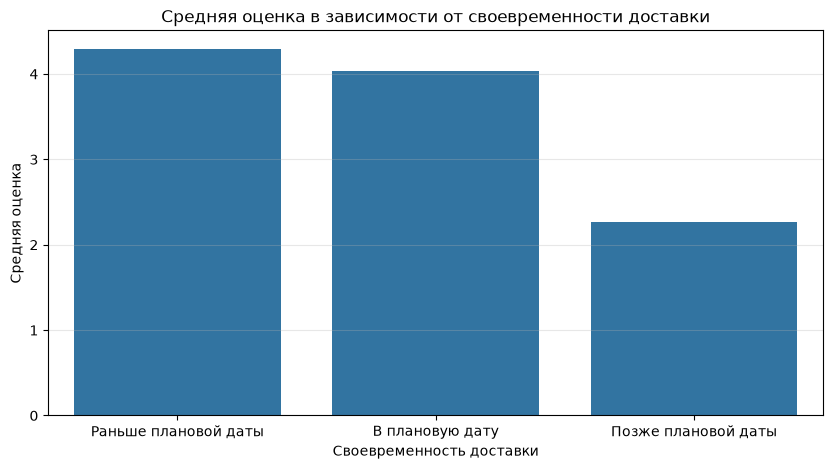

In [23]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=delivery_reviews,
    x='delivery_status',
    y='review_score',
    order=[
        'Раньше плановой даты',
        'В плановую дату',
        'Позже плановой даты'
    ],
    errorbar=None
)

plt.title('Средняя оценка в зависимости от своевременности доставки')
plt.xlabel('Своевременность доставки')
plt.ylabel('Средняя оценка')
plt.grid(axis='y', alpha=0.3)
plt.show()

### Результаты сравнения оценок покупателей

Сравнение показало заметные различия в оценках в зависимости от своевременности доставки.

Наиболее высокую среднюю оценку получили заказы, доставленные раньше плановой даты, — 4,29 балла. Для заказов, доставленных в плановую дату, средняя оценка составила 4,04 балла. Наиболее низкая средняя оценка наблюдается среди заказов с опозданием — 2,27 балла.

Распределение оценок также различается между группами. Среди заказов, доставленных раньше плановой даты, наиболее распространённая средняя оценка заказа — 5 баллов (62,38%). Среди заказов с опозданием чаще всего встречается средняя оценка 1 балл (53,69%).

Таким образом, в исследуемой выборке наблюдается связь между своевременностью доставки и оценками покупателей: заказы с опозданием получают существенно более низкие оценки. Однако для проверки статистической значимости выявленных различий проведём дополнительные статистические тесты.

## 5. Статистическая проверка выявленных различий.

Для проверки статистической значимости различий между оценками покупателей используем критерий Манна — Уитни. Он позволяет сравнивать две независимые группы и не требует нормального распределения данных.

Проведём три попарных сравнения:
- заказы, доставленные раньше плановой даты, и заказы, доставленные в плановую дату;
- заказы, доставленные раньше плановой даты, и заказы с опозданием;
- заказы, доставленные в плановую дату, и заказы с опозданием.

Нулевая гипотеза (H0): распределения оценок в двух сравниваемых группах не различаются.

Альтернативная гипотеза (H1): распределения оценок в двух сравниваемых группах различаются.

In [24]:
early_scores = delivery_reviews.loc[
    delivery_reviews['delivery_status'] == 'Раньше плановой даты',
    'review_score'
]

on_time_scores = delivery_reviews.loc[
    delivery_reviews['delivery_status'] == 'В плановую дату',
    'review_score'
]

late_scores = delivery_reviews.loc[
    delivery_reviews['delivery_status'] == 'Позже плановой даты',
    'review_score'
]

print('Раньше плановой даты:', len(early_scores))
print('В плановую дату:', len(on_time_scores))
print('Позже плановой даты:', len(late_scores))

Раньше плановой даты: 88163
В плановую дату: 1280
Позже плановой даты: 6381


Для контроля вероятности ошибки первого рода при трёх попарных сравнениях применим поправку Бонферрони. Общий уровень статистической значимости примем равным 0,05. Скорректированный уровень значимости рассчитывается делением исходного уровня 0,05 на количество сравнений. В нашем случае он составляет приблизительно 0,0167.

In [25]:
pd.set_option('display.float_format', '{:.3e}'.format)

comparisons = [
    ('Раньше vs в срок', early_scores, on_time_scores),
    ('Раньше vs опоздание', early_scores, late_scores),
    ('В срок vs опоздание', on_time_scores, late_scores)
]

results = []

for name, group1, group2 in comparisons:
    statistic, p_value = mannwhitneyu(
        group1,
        group2,
        alternative='two-sided'
    )

    results.append({
        'Сравнение': name,
        'U-статистика': statistic,
        'p-value': p_value
    })

mannwhitney_results = pd.DataFrame(results)

mannwhitney_results['p-value с поправкой Бонферрони'] = multipletests(
    mannwhitney_results['p-value'],
    method='bonferroni'
)[1]

mannwhitney_results['Скорректированное p-value'] = (
    mannwhitney_results['p-value с поправкой Бонферрони'].apply(
        lambda p: '< 0.001' if p < 0.001 else f'{p:.3e}'
    )
)

mannwhitney_results['Статистически значимо'] = (
    mannwhitney_results['p-value с поправкой Бонферрони'] < 0.05
).map({True: 'Да', False: 'Нет'})

mannwhitney_results[
    ['Сравнение', 'U-статистика',
     'Скорректированное p-value', 'Статистически значимо']
]

,Сравнение,U-статистика,Скорректированное p-value,Статистически значимо
0,Раньше vs в срок,6.372e+07,< 0.001,Да
1,Раньше vs опоздание,4.610e+08,< 0.001,Да
2,В срок vs опоздание,6.414e+06,< 0.001,Да


### Результаты статистической проверки

Критерий Манна — Уитни с поправкой Бонферрони выявил статистически значимые различия в распределениях оценок между всеми тремя группами при уровне значимости 0,05.

Таким образом, выявленные ранее различия в оценках между группами заказов подтверждаются статистической проверкой. Распределения оценок покупателей различаются в зависимости от своевременности доставки.

Результаты показывают наличие статистической связи, но не позволяют утверждать, что задержка доставки сама по себе является причиной снижения оценки. Повторяющиеся значения `review_id`, связанные с несколькими заказами, могут приводить к зависимости между наблюдениями. Поэтому предположение о независимости выборок при применении критерия Манна — Уитни может выполняться не полностью.

## 6. Итоги анализа

В ходе исследования была изучена связь между своевременностью доставки заказов Olist и оценками покупателей.

Основные результаты:

- В итоговую выборку вошли 95 824 заказа, для которых были доступны данные о доставке и оценках покупателей.
- Большинство заказов (92,01%) было доставлено раньше плановой даты, 1,34% — в плановую дату, 6,66% — с опозданием.
- Средняя оценка заказов, доставленных раньше срока, составила 4,29 балла; доставленных в плановую дату — 4,04 балла; доставленных с опозданием — 2,27 балла.
- Среди заказов с опозданием наиболее распространённой была оценка 1 (53,69%), тогда как среди заказов, доставленных раньше срока, преобладала оценка 5 (62,38%).
- Критерий Манна — Уитни с поправкой Бонферрони подтвердил статистически значимые различия в распределениях оценок между всеми тремя группами.

Таким образом, в исследуемой выборке наблюдается выраженная связь между своевременностью доставки и оценками покупателей: заказы с опозданием характеризуются существенно более низкими оценками.

При интерпретации результатов необходимо учитывать ограничения исследования. В частности, при объединении таблиц не вошли 646 заказов без соответствующих записей об отзывах. Кроме того, для заказов с несколькими записями отзывов использовалась средняя оценка, поэтому итоговые значения в отдельных случаях могли быть дробными.

Исследование выявляет статистическую связь, но не устанавливает причинно-следственную зависимость между задержкой доставки и оценкой покупателя.